# Robot Penebak Manusia — Reinforcement Learning dengan Q-Learning

**Link video presentasi (YouTube, Unlisted):** https://youtu.be/qUjicA0SW9M

**Nama / NRP:** Intifada Afkar Lazain Muhammad/5054251029

---

## Ide project

Bayangkan permainan *Tebak Siapa*. Ada 24 orang di papan. Komputer diam-diam memilih satu orang sebagai "orang rahasia". Robot (agent) harus menebak siapa orang itu. Robot boleh bertanya ya/tidak, misalnya *"Apakah dia berkacamata?"*, tetapi setiap pertanyaan ada harganya. Kalau tebakannya benar robot dapat hadiah, kalau salah robot dihukum.

Robot **tidak diberi tahu strategi terbaiknya**. Ia hanya mencoba-coba, menerima reward, lalu memperbaiki caranya sendiri. Itulah inti Reinforcement Learning.

Pertanyaan yang ingin dijawab project ini:
1. Bisakah robot belajar sendiri kapan harus bertanya dan kapan harus menebak?
2. Seberapa bagus hasilnya dibanding robot acak dan robot dengan aturan buatan manusia (heuristik)?
3. Bagaimana perilaku robot berubah kalau harga bertanya dinaikkan?

## Pemetaan konsep RL

| Konsep | Di project ini |
|---|---|
| **Agent** | Robot penebak |
| **Environment** | Papan berisi 24 kandidat + 1 orang rahasia yang dipilih acak tiap episode |
| **State** | Jawaban yang sudah diketahui untuk 6 atribut. Tiap atribut bisa *belum ditanya / ya / tidak*, jadi ada 3⁶ = 729 state |
| **Action** | 6 action "tanya atribut ke-i" + 24 action "tebak kandidat ke-j" = 30 action |
| **Reward** | −1 per pertanyaan, +10 kalau tebakan benar, −10 kalau salah. Episode selesai setelah menebak (atau setelah 10 langkah tanpa menebak, dihukum −10) |
| **Policy** | Aturan memilih action di tiap state. Setelah belajar: pilih action dengan nilai Q terbesar |
| **Value** | Q(s, a) = perkiraan total reward ke depan kalau di state s mengambil action a. V(s) = max Q(s, a) |
| **Proses belajar** | Q-learning dengan ε-greedy: awalnya banyak mencoba acak, lama-lama makin sering memakai yang sudah terbukti bagus |
| **Evaluasi** | Robot hasil belajar dibandingkan dengan robot acak dan robot heuristik, diuji 1000 episode × 5 seed |

## 1. Import dan pengaturan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEEDS = [0, 1, 2, 3, 4]       # 5 seed supaya hasil tidak kebetulan
N_TRAIN = 50_000              # jumlah episode latihan per seed
N_EVAL = 1_000                # jumlah episode uji per seed
plt.rcParams["figure.dpi"] = 110

## 2. Membuat kandidat

Ada 6 atribut ya/tidak. Kombinasi yang mungkin ada 2⁶ = 64. Kita ambil 24 kombinasi berbeda secara acak (seed tetap), jadi setiap kandidat pasti unik: kalau keenam atribut sudah ditanyakan, orangnya pasti ketahuan.

In [2]:
ATRIBUT = ["laki-laki", "berkacamata", "rambut panjang", "pakai topi", "tinggi", "tersenyum"]
NAMA = ["Andi", "Budi", "Citra", "Dewi", "Eka", "Fajar", "Gita", "Hadi", "Intan", "Joko",
        "Kiki", "Lina", "Made", "Nina", "Oki", "Putri", "Rudi", "Sari", "Tono", "Umi",
        "Vino", "Wati", "Yoga", "Zahra"]
N_ATR, N_KAND = len(ATRIBUT), len(NAMA)

rng_kand = np.random.default_rng(42)
semua_kombinasi = np.array([[(k >> i) & 1 for i in range(N_ATR)] for k in range(2 ** N_ATR)])
pilih = rng_kand.choice(len(semua_kombinasi), size=N_KAND, replace=False)
KANDIDAT = semua_kombinasi[pilih]          # bentuk (24, 6), isi 1 = ya, 0 = tidak

tabel = pd.DataFrame(np.where(KANDIDAT == 1, "ya", "-"), index=NAMA, columns=ATRIBUT)
print("Jumlah kandidat 'ya' per atribut:")
print(dict(zip(ATRIBUT, KANDIDAT.sum(axis=0))))
tabel

Jumlah kandidat 'ya' per atribut:
{'laki-laki': np.int64(13), 'berkacamata': np.int64(15), 'rambut panjang': np.int64(11), 'pakai topi': np.int64(11), 'tinggi': np.int64(13), 'tersenyum': np.int64(12)}


,laki-laki,berkacamata,rambut panjang,pakai topi,tinggi,tersenyum
Andi,-,-,ya,-,-,-
Budi,ya,-,ya,ya,ya,-
Citra,-,ya,-,-,ya,ya
Dewi,ya,-,-,ya,-,ya
Eka,ya,-,-,-,-,ya
Fajar,-,-,ya,ya,-,ya
Gita,ya,ya,-,ya,-,-
Hadi,ya,ya,ya,-,ya,ya
Intan,ya,ya,ya,-,-,ya
Joko,-,-,ya,ya,ya,-


## 3. Environment

Environment menyimpan siapa orang rahasianya dan jawaban apa saja yang sudah diberikan.

- `reset()` memilih orang rahasia secara acak dan mengosongkan jawaban.
- `step(action)` menjalankan satu action lalu mengembalikan `(state_baru, reward, selesai)`.

State disimpan sebagai satu angka 0–728 supaya bisa jadi indeks tabel Q. Kode tiap atribut: 0 = belum ditanya, 1 = ya, 2 = tidak.

In [3]:
class TebakSiapaEnv:
    def __init__(self, kandidat, biaya_tanya=1.0, reward_benar=10.0, reward_salah=-10.0, maks_langkah=10):
        self.kandidat = kandidat
        self.n_atr = kandidat.shape[1]
        self.n_kand = kandidat.shape[0]
        self.n_action = self.n_atr + self.n_kand
        self.n_state = 3 ** self.n_atr
        self.biaya_tanya = biaya_tanya
        self.reward_benar = reward_benar
        self.reward_salah = reward_salah
        self.maks_langkah = maks_langkah

    def kode_state(self):
        return int(sum(self.jawaban[i] * 3 ** i for i in range(self.n_atr)))

    def reset(self, rng):
        self.rahasia = int(rng.integers(self.n_kand))
        self.jawaban = [0] * self.n_atr
        self.langkah = 0
        return self.kode_state()

    def step(self, action):
        self.langkah += 1
        if action < self.n_atr:                     # action: bertanya
            punya = self.kandidat[self.rahasia, action] == 1
            self.jawaban[action] = 1 if punya else 2
            reward, selesai = -self.biaya_tanya, False
            if self.langkah >= self.maks_langkah:   # kebanyakan bertanya, dianggap gagal
                reward += self.reward_salah
                selesai = True
        else:                                       # action: menebak
            tebakan = action - self.n_atr
            reward = self.reward_benar if tebakan == self.rahasia else self.reward_salah
            selesai = True
        return self.kode_state(), reward, selesai

    def sisa_kandidat(self, jawaban=None):
        # daftar kandidat yang masih cocok dengan semua jawaban sejauh ini
        jawaban = self.jawaban if jawaban is None else jawaban
        cocok = np.ones(self.n_kand, dtype=bool)
        for i, j in enumerate(jawaban):
            if j == 1: cocok &= self.kandidat[:, i] == 1
            if j == 2: cocok &= self.kandidat[:, i] == 0
        return np.flatnonzero(cocok)

def decode_state(s, n_atr=N_ATR):
    return [(s // 3 ** i) % 3 for i in range(n_atr)]

env = TebakSiapaEnv(KANDIDAT)
print("Jumlah state :", env.n_state)
print("Jumlah action:", env.n_action)

Jumlah state : 729
Jumlah action: 30


### Uji coba environment secara manual

Sebelum melatih apa pun, kita cek dulu apakah environment bekerja benar.

In [4]:
rng = np.random.default_rng(123)
s = env.reset(rng)
print("Orang rahasia (hanya untuk cek):", NAMA[env.rahasia])
for a in [1, 0, 3]:
    s, r, done = env.step(a)
    print(f"Tanya '{ATRIBUT[a]}?' -> reward {r:+.0f}, sisa kandidat: {[NAMA[k] for k in env.sisa_kandidat()]}")
tebak = env.sisa_kandidat()[0]
s, r, done = env.step(N_ATR + tebak)
print(f"Tebak {NAMA[tebak]} -> reward {r:+.0f}, selesai = {done}")

Orang rahasia (hanya untuk cek): Andi
Tanya 'berkacamata?' -> reward -1, sisa kandidat: ['Andi', 'Budi', 'Dewi', 'Eka', 'Fajar', 'Joko', 'Kiki', 'Putri', 'Wati']
Tanya 'laki-laki?' -> reward -1, sisa kandidat: ['Andi', 'Fajar', 'Joko', 'Putri']
Tanya 'pakai topi?' -> reward -1, sisa kandidat: ['Andi', 'Putri']
Tebak Andi -> reward +10, selesai = True


## 4. Agent Q-Learning

Tabel Q berukuran 729 × 30, awalnya nol semua. Setiap langkah, nilai Q diperbarui dengan rumus Q-learning:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,\big[r + \gamma \max_{a'} Q(s',a') - Q(s,a)\big]$$

- α (learning rate) = 0.1: seberapa besar koreksi tiap langkah.
- γ (discount) = 0.95: seberapa penting reward di masa depan.
- ε-greedy: dengan peluang ε robot memilih action acak (eksplorasi), sisanya memilih Q terbesar (eksploitasi). ε turun dari 1.0 ke 0.05 selama latihan.

### 4a. Contoh perhitungan satu kali update

Sebelum melihat kode latihan lengkap, kita hitung rumus Q-learning secara manual untuk satu langkah. Fungsi di bawah hanya membungkus rumus yang sama dengan yang dipakai di `latih_q_learning`, tapi mencetak setiap bagiannya.

Alurnya:
1. Ambil `Q(s,a)` lama.
2. Hitung **target**: `r` saja kalau episode selesai, atau `r + γ · max Q(s')` kalau belum.
3. Hitung **TD error** = target − Q lama.
4. Q baru = Q lama + α · TD error.

In [5]:
def contoh_update(nama, q_lama, r, max_q_next, selesai, alpha=0.1, gamma=0.95):
    target = r if selesai else r + gamma * max_q_next
    td_error = target - q_lama
    q_baru = q_lama + alpha * td_error
    print(f"[{nama}]")
    if selesai:
        print(f"  target   = r = {r:+.2f}   (episode selesai, tidak ada state berikutnya)")
    else:
        print(f"  target   = r + γ·maxQ(s') = {r:+.2f} + {gamma}×{max_q_next:.2f} = {target:.4f}")
    print(f"  TD error = target − Q lama = {target:.4f} − {q_lama:.4f} = {td_error:.4f}")
    print(f"  Q baru   = Q lama + α×TD error = {q_lama:.4f} + {alpha}×{td_error:.4f} = {q_baru:.4f}\n")
    return q_baru

# 1. Bertanya, episode belum selesai. State berikutnya sudah bernilai max Q = 8.5
contoh_update("Tanya (belum selesai)", q_lama=0.0, r=-1, max_q_next=8.5, selesai=False)
# 2. Menebak benar, episode selesai
contoh_update("Tebak benar (selesai)", q_lama=0.0, r=+10, max_q_next=0, selesai=True)
# 3. Menebak salah, episode selesai
contoh_update("Tebak salah (selesai)", q_lama=0.0, r=-10, max_q_next=0, selesai=True)

[Tanya (belum selesai)]
  target   = r + γ·maxQ(s') = -1.00 + 0.95×8.50 = 7.0750
  TD error = target − Q lama = 7.0750 − 0.0000 = 7.0750
  Q baru   = Q lama + α×TD error = 0.0000 + 0.1×7.0750 = 0.7075

[Tebak benar (selesai)]
  target   = r = +10.00   (episode selesai, tidak ada state berikutnya)
  TD error = target − Q lama = 10.0000 − 0.0000 = 10.0000
  Q baru   = Q lama + α×TD error = 0.0000 + 0.1×10.0000 = 1.0000

[Tebak salah (selesai)]
  target   = r = -10.00   (episode selesai, tidak ada state berikutnya)
  TD error = target − Q lama = -10.0000 − 0.0000 = -10.0000
  Q baru   = Q lama + α×TD error = 0.0000 + 0.1×-10.0000 = -1.0000



-1.0

### 4b. Alur Q-learning pada satu episode (dengan environment asli)

Sekarang rumus dijalankan pada `TebakSiapaEnv`. Kita pakai tabel Q yang masih nol dan **urutan aksi yang sama** (tanya berkacamata, tanya laki-laki, tanya pakai topi, lalu tebak) dengan orang rahasia yang sama, diulang 3 kali. Untuk demo, α dinaikkan ke 0,5 supaya perubahan angkanya mudah dilihat (di latihan sebenarnya α = 0,1).

Yang perlu diperhatikan:
- Pada pengulangan pertama, `max Q(s')` di semua state berikutnya masih 0. Jadi tiap pertanyaan hanya "merasakan" reward-nya sendiri (−1), dan hanya tebakan terakhir yang membawa +10.
- Pada pengulangan berikutnya, nilai positif itu merambat **satu langkah ke belakang** lewat suku `γ · max Q(s')`. Begitulah reward +10 di akhir akhirnya membuat pertanyaan di awal ikut bernilai (Q-nya naik dari negatif ke positif).

In [6]:
def demo_alur_episode(env, n_ulang=3, alpha=0.5, gamma=0.95):
    Q = np.zeros((env.n_state, env.n_action))
    nama_aksi = lambda a: f"tanya '{ATRIBUT[a]}'" if a < N_ATR else f"tebak {NAMA[a - N_ATR]}"
    for ulang in range(1, n_ulang + 1):
        print(f"=== Pengulangan {ulang} ===")
        s = env.reset(np.random.default_rng(123))        # orang rahasia sama: Andi
        rencana = [1, 0, 3]                               # tanya berkacamata, laki-laki, topi
        selesai, langkah = False, 0
        while not selesai:
            a = rencana[langkah] if langkah < len(rencana) else N_ATR + int(env.sisa_kandidat()[0])
            s2, r, selesai = env.step(a)
            q_lama = Q[s, a]
            target = r if selesai else r + gamma * Q[s2].max()
            Q[s, a] += alpha * (target - q_lama)
            ket = "selesai" if selesai else f"maxQ(s')={Q[s2].max():.3f}"
            print(f"  langkah {langkah+1}: {nama_aksi(a):<22} r={r:+3.0f}  {ket:<14} "
                  f"target={target:+.3f}  Q: {q_lama:+.3f} -> {Q[s, a]:+.3f}")
            s, langkah = s2, langkah + 1
        print()
    return Q

_ = demo_alur_episode(env)

=== Pengulangan 1 ===
  langkah 1: tanya 'berkacamata'    r= -1  maxQ(s')=0.000 target=-1.000  Q: +0.000 -> -0.500
  langkah 2: tanya 'laki-laki'      r= -1  maxQ(s')=0.000 target=-1.000  Q: +0.000 -> -0.500
  langkah 3: tanya 'pakai topi'     r= -1  maxQ(s')=0.000 target=-1.000  Q: +0.000 -> -0.500
  langkah 4: tebak Andi             r=+10  selesai        target=+10.000  Q: +0.000 -> +5.000

=== Pengulangan 2 ===
  langkah 1: tanya 'berkacamata'    r= -1  maxQ(s')=0.000 target=-1.000  Q: -0.500 -> -0.750
  langkah 2: tanya 'laki-laki'      r= -1  maxQ(s')=0.000 target=-1.000  Q: -0.500 -> -0.750
  langkah 3: tanya 'pakai topi'     r= -1  maxQ(s')=5.000 target=+3.750  Q: -0.500 -> +1.625
  langkah 4: tebak Andi             r=+10  selesai        target=+10.000  Q: +5.000 -> +7.500

=== Pengulangan 3 ===
  langkah 1: tanya 'berkacamata'    r= -1  maxQ(s')=0.000 target=-1.000  Q: -0.750 -> -0.875
  langkah 2: tanya 'laki-laki'      r= -1  maxQ(s')=1.625 target=+0.544  Q: -0.750 -> -0.103


In [7]:
def latih_q_learning(env, n_episode, seed, alpha=0.1, gamma=0.95, eps_awal=1.0, eps_akhir=0.05):
    rng = np.random.default_rng(seed)
    Q = np.zeros((env.n_state, env.n_action))
    kunjungan = np.zeros(env.n_state, dtype=int)   # berapa kali tiap state dikunjungi
    peluruhan = (eps_akhir / eps_awal) ** (1 / (0.8 * n_episode))   # ε mencapai minimum di 80% latihan
    eps = eps_awal
    log = {"reward": [], "benar": [], "n_tanya": []}
    for ep in range(n_episode):
        s = env.reset(rng)
        total, n_tanya, selesai = 0.0, 0, False
        while not selesai:
            if rng.random() < eps:
                a = int(rng.integers(env.n_action))
            else:
                a = int(rng.choice(np.flatnonzero(Q[s] == Q[s].max())))   # pecah seri secara acak
            kunjungan[s] += 1
            s2, r, selesai = env.step(a)
            target = r if selesai else r + gamma * Q[s2].max()
            Q[s, a] += alpha * (target - Q[s, a])
            s = s2
            total += r
            n_tanya += a < env.n_atr
        log["reward"].append(total)
        log["benar"].append(r == env.reward_benar)
        log["n_tanya"].append(n_tanya)
        eps = max(eps_akhir, eps * peluruhan)
    log = {k: np.array(v) for k, v in log.items()}
    log["kunjungan"] = kunjungan
    return Q, log

## 5. Dua agent pembanding (baseline)

1. **Robot acak**: memilih action sembarangan. Ini batas bawah.
2. **Robot heuristik**: aturan buatan manusia. Tanyakan atribut yang membagi sisa kandidat paling seimbang (paling banyak memberi informasi), lalu tebak begitu sisa kandidat tinggal satu. Strategi ini hampir optimal, jadi dipakai sebagai batas atas yang realistis.

In [8]:
def policy_acak(env, s, rng):
    return int(rng.integers(env.n_action))

def policy_heuristik(env, s, rng):
    jawaban = decode_state(s)
    sisa = env.sisa_kandidat(jawaban)
    belum = [i for i in range(env.n_atr) if jawaban[i] == 0]
    if len(sisa) == 1 or not belum:
        return env.n_atr + int(sisa[0])
    # pilih atribut yang membuat kelompok "ya" dan "tidak" paling seimbang
    selisih = [abs(2 * env.kandidat[sisa, i].sum() - len(sisa)) for i in belum]
    return belum[int(np.argmin(selisih))]

def buat_policy_q(Q):
    def policy(env, s, rng):
        return int(rng.choice(np.flatnonzero(Q[s] == Q[s].max())))
    return policy

def evaluasi(env, policy, n_episode, seed):
    rng = np.random.default_rng(10_000 + seed)   # seed uji berbeda dari seed latihan
    reward, benar, n_tanya = [], [], []
    for _ in range(n_episode):
        s, total, tanya, selesai = env.reset(rng), 0.0, 0, False
        while not selesai:
            a = policy(env, s, rng)
            s, r, selesai = env.step(a)
            total += r
            tanya += a < env.n_atr
        reward.append(total); benar.append(r == env.reward_benar); n_tanya.append(tanya)
    return {"reward": np.mean(reward), "akurasi": np.mean(benar), "n_tanya": np.mean(n_tanya),
            "dist_tanya": np.array(n_tanya)}

## 6. Latihan (5 seed)

In [9]:
hasil_Q, hasil_log = {}, {}
for seed in SEEDS:
    Q, log = latih_q_learning(env, N_TRAIN, seed)
    hasil_Q[seed], hasil_log[seed] = Q, log
    print(f"seed {seed}: rata-rata reward 1000 episode terakhir latihan = {log['reward'][-1000:].mean():.2f}")

seed 0: rata-rata reward 1000 episode terakhir latihan = 1.42
seed 1: rata-rata reward 1000 episode terakhir latihan = 1.43
seed 2: rata-rata reward 1000 episode terakhir latihan = 1.37
seed 3: rata-rata reward 1000 episode terakhir latihan = 1.09
seed 4: rata-rata reward 1000 episode terakhir latihan = 1.30


### Kurva belajar

Garis = rata-rata 5 seed (moving average 1000 episode), area tipis = ± 1 standar deviasi antar seed. Garis putus-putus menunjukkan hasil robot heuristik sebagai acuan.

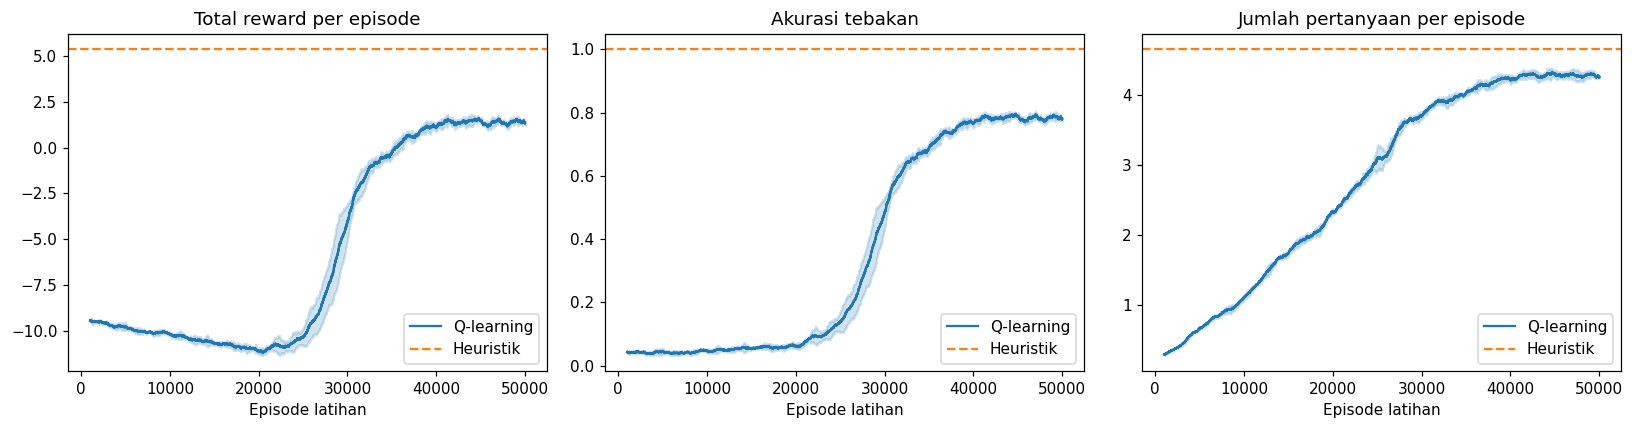

In [10]:
def moving_avg(x, w=1000):
    return np.convolve(x, np.ones(w) / w, mode="valid")

heur_ref = evaluasi(env, policy_heuristik, N_EVAL, seed=0)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, (kunci, judul) in enumerate([("reward", "Total reward per episode"),
                                    ("benar", "Akurasi tebakan"),
                                    ("n_tanya", "Jumlah pertanyaan per episode")]):
    kurva = np.array([moving_avg(hasil_log[s][kunci].astype(float)) for s in SEEDS])
    m, sd = kurva.mean(0), kurva.std(0)
    x = np.arange(len(m)) + 1000
    ax[i].plot(x, m, color="tab:blue", label="Q-learning")
    ax[i].fill_between(x, m - sd, m + sd, color="tab:blue", alpha=0.2)
    acuan = {"reward": heur_ref["reward"], "benar": heur_ref["akurasi"], "n_tanya": heur_ref["n_tanya"]}[kunci]
    ax[i].axhline(acuan, ls="--", color="tab:orange", label="Heuristik")
    ax[i].set_title(judul); ax[i].set_xlabel("Episode latihan"); ax[i].legend()
plt.tight_layout(); plt.show()

## 7. Evaluasi strategi

Setelah latihan, ε dimatikan (robot selalu memilih Q terbesar). Ketiga robot diuji pada 1000 episode baru untuk tiap seed.

In [11]:
baris = []
dist_tanya = {"Acak": [], "Heuristik": [], "Q-learning": []}
for seed in SEEDS:
    for nama, pol in [("Acak", policy_acak), ("Heuristik", policy_heuristik),
                      ("Q-learning", buat_policy_q(hasil_Q[seed]))]:
        h = evaluasi(env, pol, N_EVAL, seed)
        baris.append({"agent": nama, "seed": seed, "reward": h["reward"],
                      "akurasi": h["akurasi"], "n_tanya": h["n_tanya"]})
        dist_tanya[nama].append(h["dist_tanya"])
df = pd.DataFrame(baris)

ringkas = df.groupby("agent", sort=False)[["reward", "akurasi", "n_tanya"]].agg(["mean", "std"])
tampil = pd.DataFrame({
    "Rata-rata reward": [f"{ringkas.loc[a, ('reward','mean')]:.2f} ± {ringkas.loc[a, ('reward','std')]:.2f}" for a in ringkas.index],
    "Akurasi tebakan": [f"{100*ringkas.loc[a, ('akurasi','mean')]:.1f}% ± {100*ringkas.loc[a, ('akurasi','std')]:.1f}" for a in ringkas.index],
    "Rata-rata pertanyaan": [f"{ringkas.loc[a, ('n_tanya','mean')]:.2f} ± {ringkas.loc[a, ('n_tanya','std')]:.2f}" for a in ringkas.index],
}, index=ringkas.index)
tampil

,Rata-rata reward,Akurasi tebakan,Rata-rata pertanyaan
agent,,,
Acak,-9.42 ± 0.08,4.2% ± 0.4,0.25 ± 0.01
Heuristik,5.34 ± 0.02,100.0% ± 0.0,4.66 ± 0.02
Q-learning,5.19 ± 0.06,100.0% ± 0.0,4.81 ± 0.06


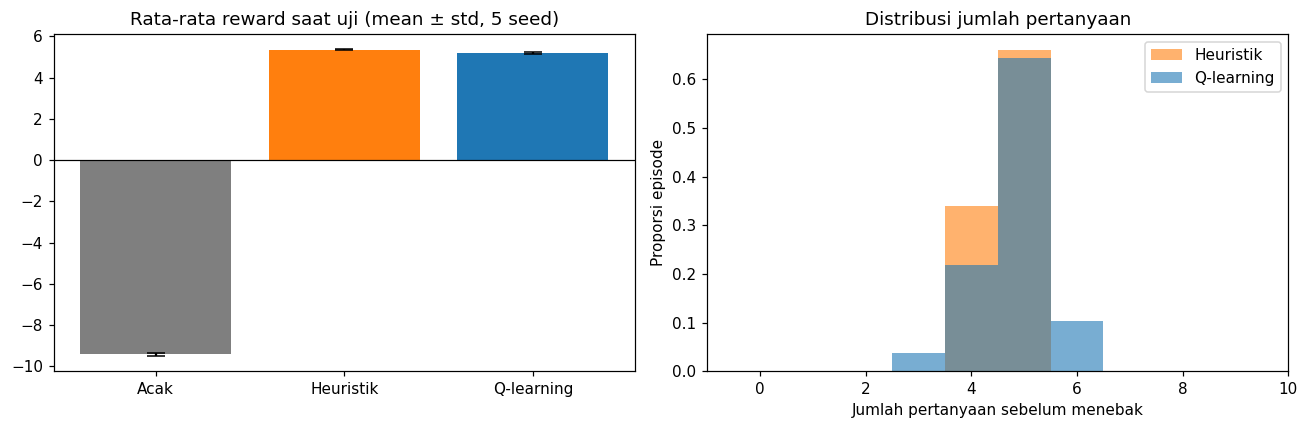

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
urutan = ["Acak", "Heuristik", "Q-learning"]
warna = ["tab:gray", "tab:orange", "tab:blue"]
m = [ringkas.loc[a, ("reward", "mean")] for a in urutan]
sd = [ringkas.loc[a, ("reward", "std")] for a in urutan]
ax[0].bar(urutan, m, yerr=sd, color=warna, capsize=6)
ax[0].axhline(0, color="black", lw=0.8)
ax[0].set_title("Rata-rata reward saat uji (mean ± std, 5 seed)")

bins = np.arange(0, 11) - 0.5
for nama, w in [("Heuristik", "tab:orange"), ("Q-learning", "tab:blue")]:
    ax[1].hist(np.concatenate(dist_tanya[nama]), bins=bins, alpha=0.6, color=w, label=nama, density=True)
ax[1].set_xlabel("Jumlah pertanyaan sebelum menebak"); ax[1].set_ylabel("Proporsi episode")
ax[1].set_title("Distribusi jumlah pertanyaan"); ax[1].legend()
plt.tight_layout(); plt.show()

## 8. Melihat isi kepala robot: policy dan value

### 8a. Nilai Q di state awal

Di awal permainan belum ada jawaban apa pun (state 0). Grafik ini menunjukkan nilai Q untuk ke-30 action. Action dengan Q tertinggi adalah keputusan pertama robot.

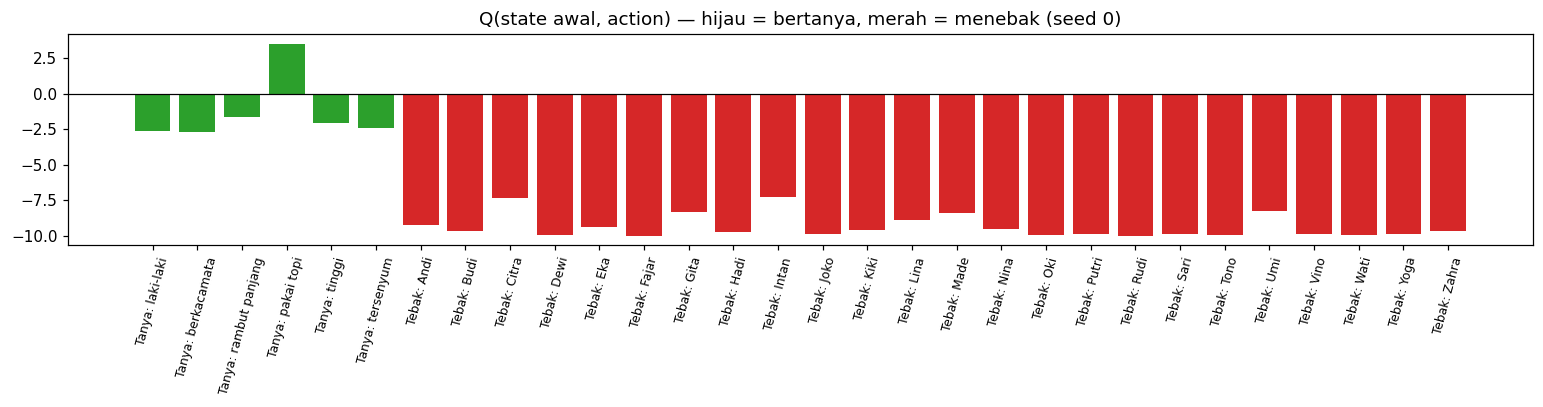

Action pertama pilihan robot per seed:
  seed 0: Tanya: pakai topi  (V(awal) = 3.51)
  seed 1: Tanya: rambut panjang  (V(awal) = 3.44)
  seed 2: Tanya: rambut panjang  (V(awal) = 3.43)
  seed 3: Tanya: laki-laki  (V(awal) = 3.46)
  seed 4: Tanya: tinggi  (V(awal) = 3.50)
Action pertama pilihan heuristik: Tanya: tersenyum


In [13]:
Q0 = hasil_Q[0]
label = [f"Tanya: {a}" for a in ATRIBUT] + [f"Tebak: {n}" for n in NAMA]
fig, ax = plt.subplots(figsize=(14, 3.8))
warna_bar = ["tab:green"] * N_ATR + ["tab:red"] * N_KAND
ax.bar(range(env.n_action), Q0[0], color=warna_bar)
ax.set_xticks(range(env.n_action)); ax.set_xticklabels(label, rotation=75, fontsize=8)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Q(state awal, action) — hijau = bertanya, merah = menebak (seed 0)")
plt.tight_layout(); plt.show()

print("Action pertama pilihan robot per seed:")
for seed in SEEDS:
    print(f"  seed {seed}: {label[int(hasil_Q[seed][0].argmax())]}  (V(awal) = {hasil_Q[seed][0].max():.2f})")
print("Action pertama pilihan heuristik:", label[policy_heuristik(env, 0, None)])

### 8b. Value vs ketidakpastian

Untuk setiap state yang sering dikunjungi (minimal 2000 kali selama latihan, supaya nilai Q-nya sudah stabil), kita hitung V(s) = max Q(s, a) dan berapa kandidat yang masih tersisa di state itu. Harapannya: makin sedikit kandidat tersisa, makin tinggi value-nya, karena robot makin dekat ke tebakan yang benar.

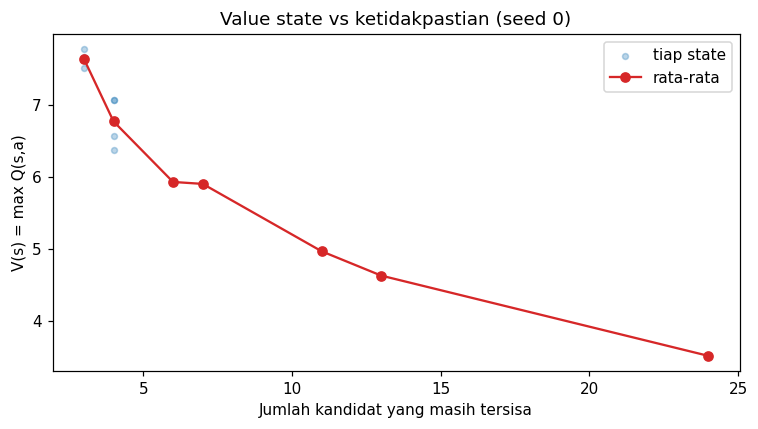

,V
sisa,
3.0,7.65
4.0,6.78
6.0,5.93
7.0,5.91
11.0,4.97
13.0,4.63
24.0,3.51


In [14]:
titik = []
for s in range(env.n_state):
    if hasil_log[0]["kunjungan"][s] >= 2000:
        sisa = len(env.sisa_kandidat(decode_state(s)))
        if sisa > 0:
            titik.append((sisa, Q0[s].max()))
titik = np.array(titik)
rata = pd.DataFrame(titik, columns=["sisa", "V"]).groupby("sisa")["V"].mean()

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(titik[:, 0], titik[:, 1], alpha=0.3, s=15, label="tiap state")
ax.plot(rata.index, rata.values, "o-", color="tab:red", label="rata-rata")
ax.set_xlabel("Jumlah kandidat yang masih tersisa"); ax.set_ylabel("V(s) = max Q(s,a)")
ax.set_title("Value state vs ketidakpastian (seed 0)"); ax.legend()
plt.tight_layout(); plt.show()
rata.round(2)

### 8c. Contoh permainan robot setelah belajar

In [15]:
def main_satu_episode(env, Q, seed):
    rng = np.random.default_rng(seed)
    s, selesai, total = env.reset(rng), False, 0
    print(f"Orang rahasia: {NAMA[env.rahasia]}")
    while not selesai:
        a = int(Q[s].argmax())
        sebelum = len(env.sisa_kandidat())
        s, r, selesai = env.step(a)
        total += r
        if a < N_ATR:
            jwb = "ya" if env.jawaban[a] == 1 else "tidak"
            print(f"  Robot: 'Apakah dia {ATRIBUT[a]}?'  Jawab: {jwb}.  Sisa kandidat {sebelum} -> {len(env.sisa_kandidat())}")
        else:
            print(f"  Robot menebak: {NAMA[a - N_ATR]}  ->  {'BENAR' if r > 0 else 'SALAH'}")
    print(f"  Total reward: {total:+.0f}\n")

for sd in [7, 8, 9]:
    main_satu_episode(env, hasil_Q[0], sd)

Orang rahasia: Yoga
  Robot: 'Apakah dia pakai topi?'  Jawab: tidak.  Sisa kandidat 24 -> 13
  Robot: 'Apakah dia tinggi?'  Jawab: ya.  Sisa kandidat 13 -> 6
  Robot: 'Apakah dia tersenyum?'  Jawab: ya.  Sisa kandidat 6 -> 4
  Robot: 'Apakah dia berkacamata?'  Jawab: ya.  Sisa kandidat 4 -> 3
  Robot: 'Apakah dia laki-laki?'  Jawab: tidak.  Sisa kandidat 3 -> 2
  Robot: 'Apakah dia rambut panjang?'  Jawab: ya.  Sisa kandidat 2 -> 1
  Robot menebak: Yoga  ->  BENAR
  Total reward: +4

Orang rahasia: Sari
  Robot: 'Apakah dia pakai topi?'  Jawab: ya.  Sisa kandidat 24 -> 11
  Robot: 'Apakah dia rambut panjang?'  Jawab: tidak.  Sisa kandidat 11 -> 7
  Robot: 'Apakah dia tersenyum?'  Jawab: ya.  Sisa kandidat 7 -> 3
  Robot: 'Apakah dia tinggi?'  Jawab: ya.  Sisa kandidat 3 -> 2
  Robot: 'Apakah dia laki-laki?'  Jawab: ya.  Sisa kandidat 2 -> 1
  Robot menebak: Sari  ->  BENAR
  Total reward: +5

Orang rahasia: Kiki
  Robot: 'Apakah dia pakai topi?'  Jawab: tidak.  Sisa kandidat 24 -> 13
 

### 8d. Nilai Q yang dipakai robot di tiap langkah

Pada 8c robot hanya memakai `argmax` dari tabel Q. Di sini kita tampilkan angkanya: di tiap langkah, berapa Q aksi yang dipilih, dibanding Q terbaik untuk **menebak** (aksi merah di grafik 8a). Robot menebak persis ketika Q menebak sudah mengalahkan Q bertanya.

In [16]:
def tampilkan_q_episode(env, Q, seed):
    rng = np.random.default_rng(seed)
    s, selesai = env.reset(rng), False
    print(f"Orang rahasia: {NAMA[env.rahasia]}")
    while not selesai:
        a = int(Q[s].argmax())
        q_tebak = Q[s, N_ATR:].max()
        q_tanya = Q[s, :N_ATR].max()
        pilihan = f"tanya '{ATRIBUT[a]}'" if a < N_ATR else f"tebak {NAMA[a - N_ATR]}"
        print(f"  sisa kandidat {len(env.sisa_kandidat()):>2} | Q tanya terbaik = {q_tanya:+6.2f} | "
              f"Q tebak terbaik = {q_tebak:+6.2f} | pilih: {pilihan}")
        s, r, selesai = env.step(a)
    print()

tampilkan_q_episode(env, hasil_Q[0], seed=7)

Orang rahasia: Yoga
  sisa kandidat 24 | Q tanya terbaik =  +3.51 | Q tebak terbaik =  -7.27 | pilih: tanya 'pakai topi'
  sisa kandidat 13 | Q tanya terbaik =  +4.63 | Q tebak terbaik =  -4.63 | pilih: tanya 'tinggi'
  sisa kandidat  6 | Q tanya terbaik =  +5.93 | Q tebak terbaik =  -3.06 | pilih: tanya 'tersenyum'
  sisa kandidat  4 | Q tanya terbaik =  +6.38 | Q tebak terbaik =  -0.71 | pilih: tanya 'berkacamata'
  sisa kandidat  3 | Q tanya terbaik =  +7.68 | Q tebak terbaik =  -1.56 | pilih: tanya 'laki-laki'
  sisa kandidat  2 | Q tanya terbaik =  +8.50 | Q tebak terbaik =  +0.63 | pilih: tanya 'rambut panjang'
  sisa kandidat  1 | Q tanya terbaik =  +2.80 | Q tebak terbaik = +10.00 | pilih: tebak Yoga



## 9. Eksperimen tambahan: kalau bertanya makin mahal?

Kita latih ulang robot dengan harga bertanya −1, −2, −3, −4, dan −6 (reward benar/salah tetap ±10). Pertanyaannya: apakah robot menyesuaikan strateginya sendiri?

Supaya cepat, eksperimen ini memakai 3 seed.

In [17]:
baris_biaya = []
for biaya in [1, 2, 3, 4, 6]:
    env_b = TebakSiapaEnv(KANDIDAT, biaya_tanya=biaya)
    for seed in SEEDS[:3]:
        Q_b, _ = latih_q_learning(env_b, N_TRAIN, seed)
        h = evaluasi(env_b, buat_policy_q(Q_b), N_EVAL, seed)
        baris_biaya.append({"biaya_tanya": biaya, "seed": seed, **{k: h[k] for k in ["reward", "akurasi", "n_tanya"]}})
df_biaya = pd.DataFrame(baris_biaya)
ringkas_biaya = df_biaya.groupby("biaya_tanya")[["reward", "akurasi", "n_tanya"]].agg(["mean", "std"]).round(2)
ringkas_biaya

reward       akurasi       n_tanya      
              mean   std    mean   std    mean   std
biaya_tanya                                         
1             5.19  0.08    1.00  0.00    4.81  0.08
2             0.64  0.08    1.00  0.00    4.68  0.04
3            -6.23  1.30    0.89  0.07    4.70  0.25
4            -9.19  0.13    0.04  0.01    0.00  0.00
6            -9.27  0.14    0.04  0.01    0.00  0.00

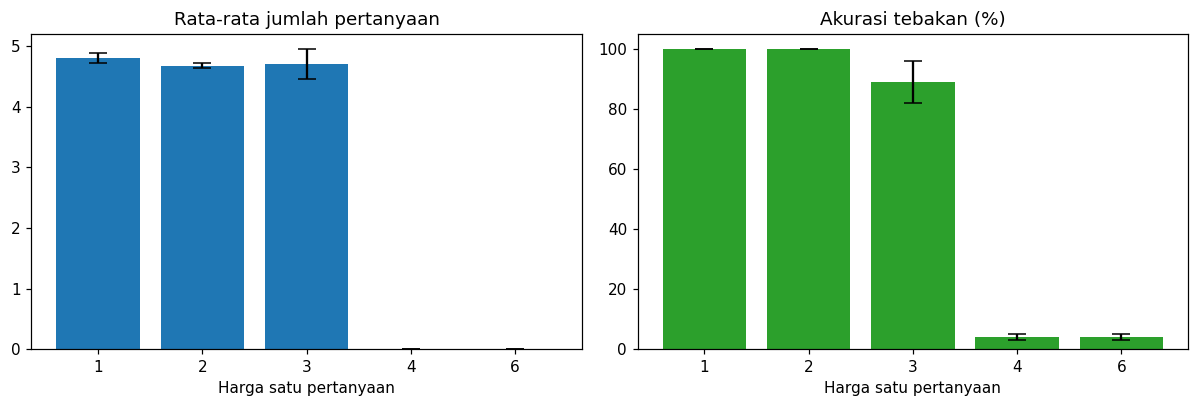

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
x = ringkas_biaya.index.astype(str)
ax[0].bar(x, ringkas_biaya[("n_tanya", "mean")], yerr=ringkas_biaya[("n_tanya", "std")], capsize=6, color="tab:blue")
ax[0].set_xlabel("Harga satu pertanyaan"); ax[0].set_title("Rata-rata jumlah pertanyaan")
ax[1].bar(x, 100 * ringkas_biaya[("akurasi", "mean")], yerr=100 * ringkas_biaya[("akurasi", "std")], capsize=6, color="tab:green")
ax[1].set_xlabel("Harga satu pertanyaan"); ax[1].set_title("Akurasi tebakan (%)")
plt.tight_layout(); plt.show()

## 10. Analisis

*Angka di bawah berasal dari run notebook ini (seed tetap). Kalau notebook dijalankan ulang, angkanya akan sama.*

**1. Proses belajar (kurva belajar).**
Di awal latihan (sekitar episode 0–20.000), reward justru sedikit turun, dari sekitar −9,5 ke −11. Penyebabnya: ε masih besar, jadi robot sering bertanya acak lalu menebak acak juga. Ia membayar biaya pertanyaan, tapi tebakannya tetap salah. Mulai sekitar episode 25.000, nilai Q untuk "tebak saat kandidat tinggal sedikit" sudah cukup akurat, sehingga reward dan akurasi naik tajam. Kurva jumlah pertanyaan naik terus dari ±0,3 ke ±4,3: robot belajar bahwa lebih baik membayar beberapa pertanyaan daripada menebak buta. Selama latihan reward-nya berhenti di sekitar +1,4, lebih rendah dari hasil uji, karena ε = 0,05 masih membuat robot sesekali bertindak acak.

**2. Evaluasi strategi.**
Saat diuji tanpa eksplorasi (1000 episode × 5 seed):
- Robot acak: reward −9,42, akurasi 4,2%. Hampir selalu langsung menebak sembarangan.
- Robot heuristik: reward 5,34, akurasi 100%, rata-rata 4,66 pertanyaan.
- Robot Q-learning: reward 5,19 ± 0,06, akurasi 100%, rata-rata 4,81 pertanyaan.

Q-learning mencapai sekitar 97% reward heuristik tanpa pernah diberi tahu aturan apa pun. Selisih kecilnya berasal dari jumlah pertanyaan: kadang robot bertanya satu kali lebih banyak, karena pertanyaan yang ia pilih tidak membagi kandidat seimbang seperti heuristik. Standar deviasi antar seed kecil (0,06), jadi hasilnya stabil dan bukan kebetulan.

**3. Policy yang dipelajari.**
Di state awal, nilai Q untuk semua action "tebak" sekitar −7 sampai −10, sedangkan action "tanya" jauh lebih tinggi. Robot paham bahwa menebak di awal hampir pasti salah. Pertanyaan pertama berbeda antar seed (pakai topi, rambut panjang, laki-laki, tinggi), dan berbeda juga dengan pilihan heuristik (tersenyum). Ini wajar. Setiap atribut dimiliki 11–15 dari 24 kandidat, jadi semua pertanyaan pertama sama-sama membagi kandidat kira-kira setengah-setengah, dan nilai Q-nya hampir sama. Dari contoh permainan terlihat robot terus bertanya sampai kandidat tinggal 1, lalu baru menebak. Pola ini sama dengan strategi heuristik.

**4. Value.**
Grafik value vs ketidakpastian turun dengan rapi: V(s) ≈ 7,7 ketika kandidat tinggal 3, dan ≈ 3,5 di awal permainan (24 kandidat). Artinya robot "merasa" makin dekat ke kemenangan ketika informasinya makin banyak. Nilai V(awal) = 3,5 juga masuk akal. Kira-kira 5 pertanyaan (−5) lalu +10 yang didiskon γ = 0,95, hasilnya sekitar 3,5. Grafik hanya memakai state yang dikunjungi minimal 2000 kali. State yang jarang dikunjungi nilai Q-nya belum stabil, sehingga tidak dimasukkan.

**5. Eksperimen harga pertanyaan.**
- Harga 1 dan 2: robot tetap bertanya ±4,7 kali dan akurasinya 100%.
- Harga 3: robot masih bertanya, tetapi akurasi turun ke 89% dan variasi antar seed membesar (reward −6,23 ± 1,30). Ini titik di mana bertanya dan menebak hampir sama mahalnya, jadi strateginya mulai goyah.
- Harga 4 dan 6: robot berhenti bertanya sama sekali (0 pertanyaan) dan langsung menebak, dengan akurasi ±4% (≈ 1/24).

Perilaku di harga 4 ini sebenarnya rasional. Lima pertanyaan berharga −20, padahal hadiah benar cuma +10 (dan didiskon). Menebak langsung memberi rata-rata sekitar −9,2, sedikit lebih baik. Robot menemukan sendiri bahwa "kalau informasi terlalu mahal, lebih baik nekat". Strategi tidak diprogram, tetapi muncul dari reward.

## 11. Kesimpulan

1. Robot berhasil belajar sendiri hanya dari reward. Setelah 50.000 episode latihan, robot Q-learning menebak dengan benar 100% dan reward rata-ratanya 5,19, hampir menyamai strategi heuristik buatan manusia (5,34). Robot acak hanya mendapat −9,42.
2. Policy yang dipelajari masuk akal: bertanya sampai kandidat tinggal satu, lalu menebak. Value juga masuk akal: makin sedikit kandidat tersisa, makin tinggi nilai state-nya.
3. Desain reward menentukan perilaku. Ketika harga bertanya dinaikkan sampai ≥ 4, robot berubah strategi menjadi langsung menebak, karena itulah pilihan dengan reward harapan terbaik di aturan tersebut.
4. Keterbatasan: Q-learning tabular hanya cocok karena state-nya kecil (729). Kalau atribut atau kandidat ditambah banyak, tabel Q akan membengkak dan butuh metode lain seperti Deep Q-Network. Robot juga butuh puluhan ribu episode untuk mencapai hasil yang bisa dicapai heuristik tanpa latihan sama sekali.